In [ ]:
%matplotlib inline
from pathlib import Path
import sys

cwd = Path.cwd().resolve()
repo_root = next((p for p in (cwd, *cwd.parents)
                  if (p / "application_mnist" / "data" / "pipeline.py").exists()), None)
if repo_root is None:
    raise FileNotFoundError("")
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from application_mnist.data.pipeline import load_prepared
from application_mnist.decision_tree.training import (
    TreeSettings, fit_tree, split_metrics, tune_trees, save_tuning_table, save_model_bundle
)
from application_mnist.decision_tree.boolean_formula import (
    tree_to_dnf, assert_equivalent, export_formulas
)
from application_mnist.decision_tree.visualize import (
    plot_validation_grid, plot_tree_diagram, plot_confusion, plot_used_regions,
    explain_tree_path, plot_example, plot_validation_errors
)

print("Repository:", repo_root)
print("Python:", sys.executable)

Repository: C:\Users\sofia\OneDrive\Desktop\Research\Code\ClassifierRevisionHumanFeedback
Python: c:\Users\sofia\AppData\Local\Programs\Python\Python310\python.exe


## DATASET


In [ ]:
DATASET_FILENAME = "3_vs_8_g7_t20_seed42.npz"
processed_dir = repo_root / "application_mnist" / "data" / "processed"
files = sorted(processed_dir.glob("*.npz"), key=lambda p: p.stat().st_mtime, reverse=True)
print("Available prepared datasets:", *[f"  {p.name}" for p in files], sep="\n")
if DATASET_FILENAME is None:
    if not files:
        raise FileNotFoundError("")
    dataset_path = files[0]
else:
    dataset_path = processed_dir / DATASET_FILENAME
if not dataset_path.exists():
    raise FileNotFoundError(dataset_path)

data = load_prepared(dataset_path)
feature_names = [str(x) for x in data["feature_names"]]
output_dir = repo_root / "application_mnist" / "decision_tree" / "outputs" / dataset_path.stem
output_dir.mkdir(parents=True, exist_ok=True)

print("Using dataset:", dataset_path.name)
print("Task:", data["metadata"]["task_name"])
print("Boolean features:", len(feature_names))
for s in ("train", "val", "test"):
    print(f"{s:5s}: {data[f'{s}_features'].shape[0]} examples; "
          f"class 1: {int(data[f'{s}_labels'].sum())}")

Available prepared datasets:
  odd_vs_other_parity_g7_t20_seed10.npz
  3_vs_8_g7_t20_seed42.npz
Using dataset: 3_vs_8_g7_t20_seed42.npz
Task: 3_vs_8
Boolean features: 49
train: 1600 examples; class 1: 818
val  : 400 examples; class 1: 205
test : 400 examples; class 1: 204


## TRAINING


In [4]:
DEPTHS = (2, 3, 4, 5, 6, 8, None)
MIN_LEAF_SIZES = (1, 5, 10, 20)

model, best_settings, tuning_rows = tune_trees(
    data,
    depths=DEPTHS,
    min_leaf_sizes=MIN_LEAF_SIZES,
    seed=10,
)
save_tuning_table(tuning_rows, output_dir / "validation_grid.csv")
ranking = pd.DataFrame(tuning_rows).sort_values(
    ["balanced_accuracy", "leaves", "used_variables"], ascending=[False, True, True]
)
display(ranking.head(12))
print("Chosen settings:", best_settings)

,max_depth,min_samples_leaf,ccp_alpha,criterion,seed,accuracy,balanced_accuracy,precision_pos,recall_pos,f1_pos,depth,leaves,nodes,used_variables
22,8.0,10,0.0,gini,10,0.9075,0.908755,0.956522,0.858537,0.904884,8,55,109,21
26,NaN,10,0.0,gini,10,0.9075,0.908755,0.956522,0.858537,0.904884,11,61,121,21
18,6.0,10,0.0,gini,10,0.9050,0.906316,0.956284,0.853659,0.902062,6,35,69,19
16,6.0,1,0.0,gini,10,0.9050,0.906191,0.951351,0.858537,0.902564,6,43,85,23
20,8.0,1,0.0,gini,10,0.9025,0.903127,0.927835,0.878049,0.902256,8,83,165,30
17,6.0,5,0.0,gini,10,0.9000,0.900938,0.936508,0.863415,0.898477,6,40,79,21
14,5.0,10,0.0,gini,10,0.8950,0.896685,0.960452,0.829268,0.890052,5,25,49,15
13,5.0,5,0.0,gini,10,0.8900,0.891557,0.949721,0.829268,0.885417,5,27,53,18
19,6.0,20,0.0,gini,10,0.8900,0.890807,0.921466,0.858537,0.888889,6,29,57,15
23,8.0,20,0.0,gini,10,0.8900,0.890807,0.921466,0.858537,0.888889,8,33,65,15


Chosen settings: TreeSettings(max_depth=8, min_samples_leaf=10, ccp_alpha=0.0, criterion='gini', seed=10)


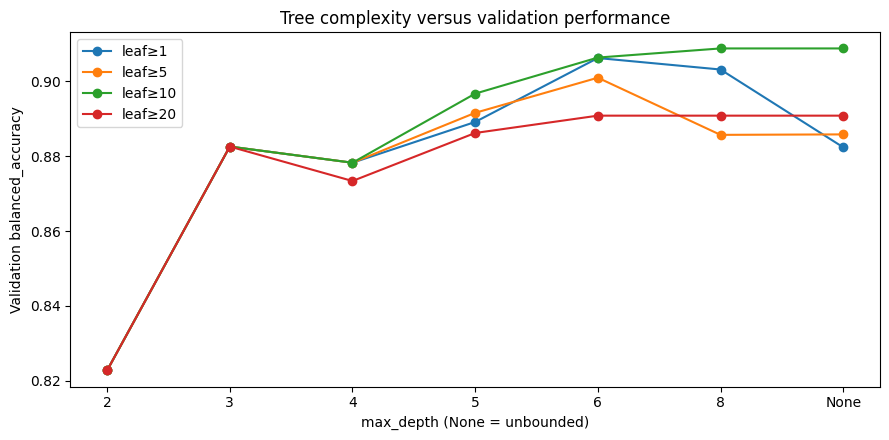

Train metrics: {'split': 'train', 'n': 1600, 'accuracy': 0.9225, 'balanced_accuracy': 0.9229109736804257, 'precision_pos': 0.9414758269720102, 'recall_pos': 0.9046454767726161, 'f1_pos': 0.9226932668329177, 'confusion_matrix': [[736, 46], [78, 740]], 'depth': 8, 'leaves': 55, 'nodes': 109, 'used_variables': 21}
Validation metrics: {'split': 'val', 'n': 400, 'accuracy': 0.9075, 'balanced_accuracy': 0.9087554721701063, 'precision_pos': 0.9565217391304348, 'recall_pos': 0.8585365853658536, 'f1_pos': 0.9048843187660668, 'confusion_matrix': [[187, 8], [29, 176]], 'depth': 8, 'leaves': 55, 'nodes': 109, 'used_variables': 21}
Test metrics: not evaluated yet


In [5]:
fig = plot_validation_grid(tuning_rows)
plt.show()

print("Train metrics:", split_metrics(model, data, "train"))
print("Validation metrics:", split_metrics(model, data, "val"))
print("Test metrics: not evaluated yet")

## TREE SELECTED

Depth: 8 Leaves: 55
Used features: 21/49
['ink_r1_c2', 'ink_r1_c3', 'ink_r1_c4', 'ink_r1_c5', 'ink_r2_c1', 'ink_r2_c2', 'ink_r2_c3', 'ink_r2_c5', 'ink_r3_c1', 'ink_r3_c2', 'ink_r4_c1', 'ink_r4_c2', 'ink_r4_c3', 'ink_r4_c4', 'ink_r4_c5', 'ink_r5_c1', 'ink_r5_c2', 'ink_r5_c4', 'ink_r5_c5', 'ink_r6_c2', 'ink_r6_c3']


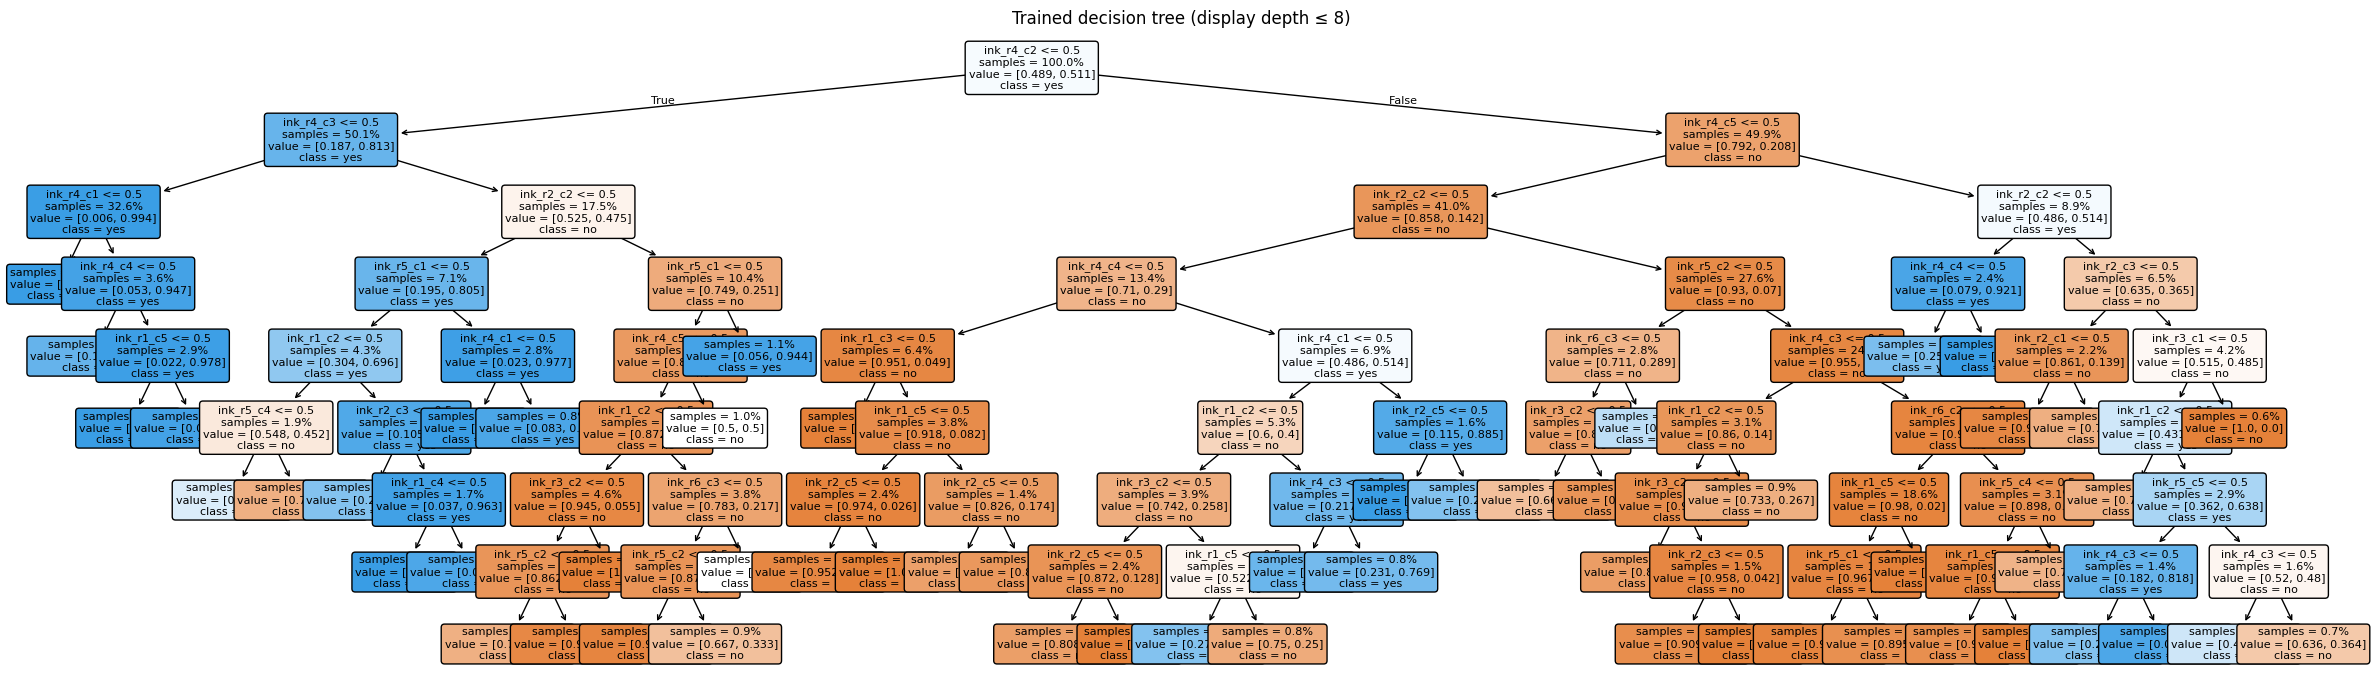

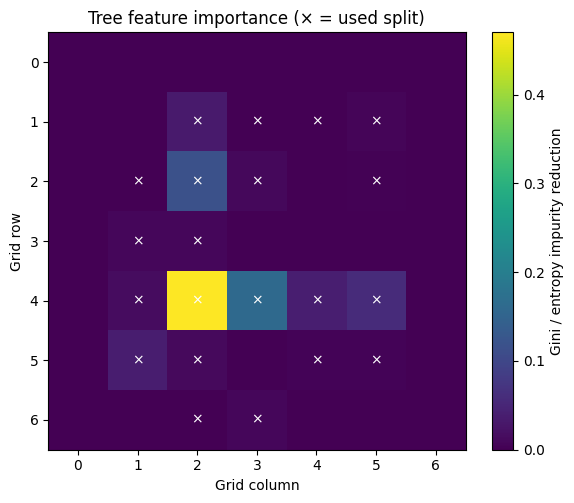

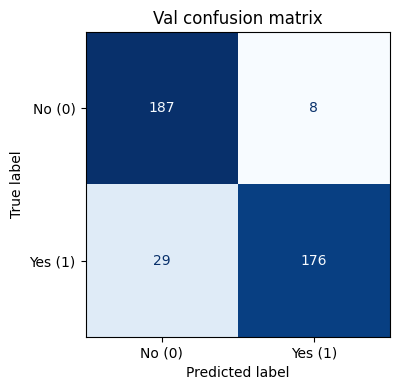

In [8]:
print("Depth:", model.get_depth(), "Leaves:", model.get_n_leaves())
used = sorted(set(int(i) for i in model.tree_.feature if i >= 0))
print(f"Used features: {len(used)}/{len(feature_names)}")
print([feature_names[i] for i in used])

fig = plot_tree_diagram(model, feature_names, max_depth=8)
plt.show()
fig = plot_used_regions(model, data)
plt.show()
fig = plot_confusion(model, data, split="val")
plt.show()

## EXAMPLES

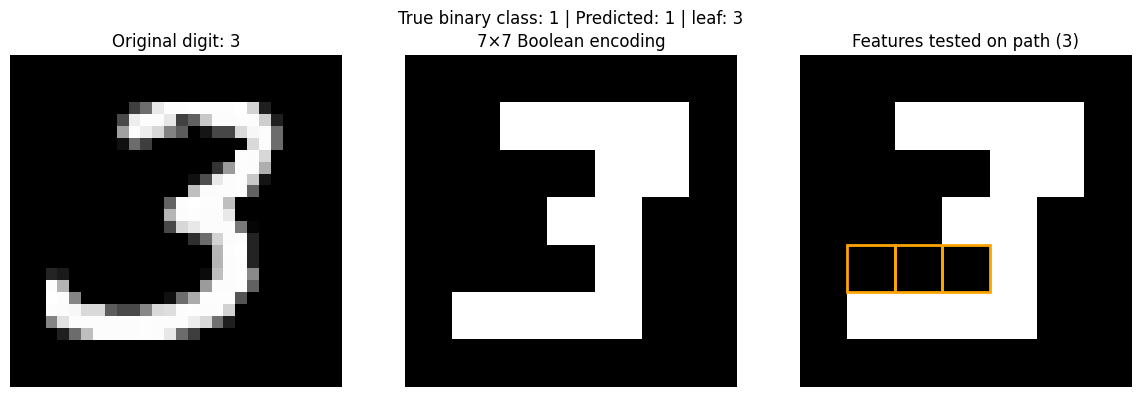

Predicted class: 1 | Leaf: 3 | Leaf class proportion: 1.000
- ink_r4_c2 = 0
- ink_r4_c3 = 0
- ink_r4_c1 = 0


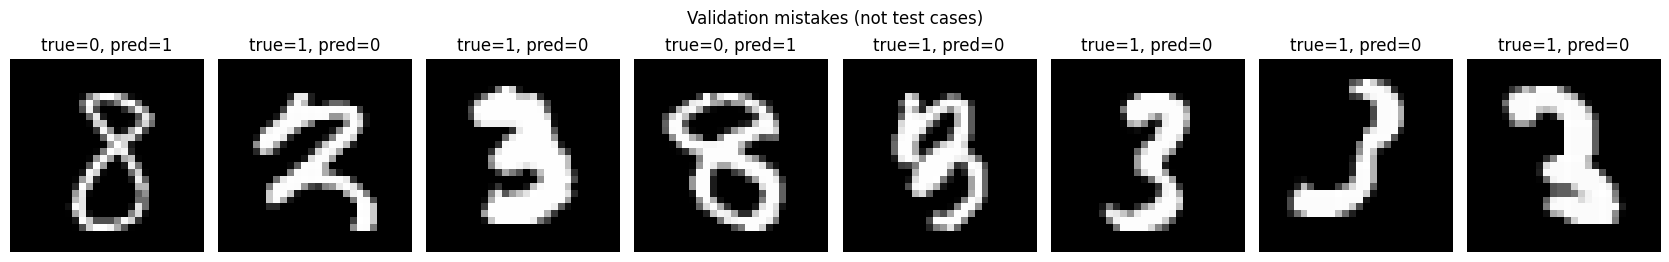

Validation error indices: [57, 312, 85, 338, 337, 232, 71, 212]


In [9]:
SPLIT = "val"  # train or val; reserve test for final evaluation
EXAMPLE_INDEX = 0

fig, path_info = plot_example(model, data, split=SPLIT, index=EXAMPLE_INDEX)
plt.show()
print(f"Predicted class: {path_info['predicted']} | "
      f"Leaf: {path_info['leaf']} | "
      f"Leaf class proportion: {path_info['confidence']:.3f}")
for condition in path_info["splits"]:
    print("-", condition["condition"])

fig, error_indices = plot_validation_errors(model, data, count=8)
if fig is None:
    print("No mistakes on validation examples")
else:
    plt.show()
    print("Validation error indices:", error_indices.tolist())

## CONVERSION TO BOOLEAN FORMULA


In [10]:
positive_dnf = tree_to_dnf(model, feature_names, positive_class=1)
negative_dnf = tree_to_dnf(model, feature_names, positive_class=0)

print("Positive DNF terms (positive tree leaves after simple absorption):", len(positive_dnf.terms))
print("Distinct variables used in positive DNF:", len(positive_dnf.used_indices))
print("Positive formula preview:")
print(positive_dnf.text(max_terms=6))

# Verify that the exact formulas reproduce *every* prediction on train/val.
# This tests equivalence to the fitted tree, NOT correctness of its digit labels.
for split in ("train", "val"):
    X = data[f"{split}_features"]
    assert_equivalent(model, positive_dnf, X)
    assert np.all(negative_dnf.evaluate(X) == (1 - model.predict(X)))
print("Formula/tree equivalence passed on training and validation rows.")

Positive DNF terms (positive tree leaves after simple absorption): 22
Distinct variables used in positive DNF: 18
Positive formula preview:
(¬ink_r4_c1 ∧ ¬ink_r4_c2 ∧ ¬ink_r4_c3) ∨ (¬ink_r2_c2 ∧ ink_r4_c2 ∧ ¬ink_r4_c4 ∧ ink_r4_c5) ∨ (¬ink_r2_c2 ∧ ink_r4_c2 ∧ ink_r4_c4 ∧ ink_r4_c5) ∨ (ink_r2_c2 ∧ ¬ink_r4_c2 ∧ ink_r4_c3 ∧ ink_r5_c1) ∨ (ink_r4_c1 ∧ ¬ink_r4_c2 ∧ ¬ink_r4_c3 ∧ ¬ink_r4_c4) ∨ (¬ink_r1_c5 ∧ ink_r4_c1 ∧ ¬ink_r4_c2 ∧ ¬ink_r4_c3 ∧ ink_r4_c4) ... [16 more terms]
Formula/tree equivalence passed on training and validation rows.


## EVALUATION


FINAL TEST METRICS:
  split: test
  n: 400
  accuracy: 0.9075
  balanced_accuracy: 0.9071128451380552
  precision_pos: 0.8957345971563981
  recall_pos: 0.9264705882352942
  f1_pos: 0.9108433734939759
  confusion_matrix: [[174, 22], [15, 189]]
  depth: 8
  leaves: 55
  nodes: 109
  used_variables: 21


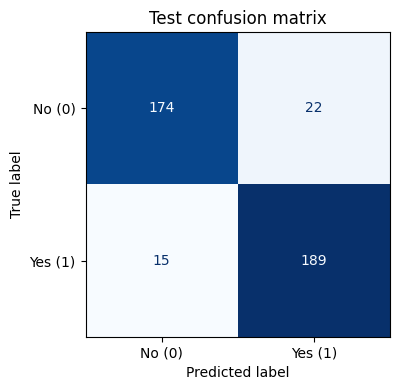

Tree/formula agreement on test examples: 100% (by construction).


In [12]:
test_results = split_metrics(model, data, "test")
print("FINAL TEST METRICS:")
for key, value in test_results.items():
    print(f"  {key}: {value}")
fig = plot_confusion(model, data, split="test")
plt.show()
assert_equivalent(model, positive_dnf, data["test_features"])
assert np.all(negative_dnf.evaluate(data["test_features"]) ==
              (1 - model.predict(data["test_features"])))
print("Tree/formula agreement on test examples: 100% (by construction).")

## EXPORT MODEL



In [13]:
model_files = save_model_bundle(model, best_settings, data, output_dir,
                                test_results=test_results)
formula_files = export_formulas(model, feature_names, output_dir)
print("Output directory:", output_dir)
for description, path in {**model_files, **formula_files}.items():
    print(f"  {description}: {path.name}")
print("  validation_grid.csv")

Output directory: C:\Users\sofia\OneDrive\Desktop\Research\Code\ClassifierRevisionHumanFeedback\application_mnist\decision_tree\outputs\3_vs_8_g7_t20_seed42
  model: decision_tree.joblib
  metadata: model_info.json
  positive_json: positive_formula.json
  negative_json: negative_formula.json
  positive_text: positive_formula.txt
  negative_text: negative_formula.txt
  validation_grid.csv
